In [ ]:
import pandas as pd
import numpy as np


sales = pd.read_csv('/content/sales_data_with_discounts.csv')
sales.head()

,Date,Day,SKU,City,Volume,BU,Brand,Model,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
0,01-04-2021,Thursday,M01,C,15,Mobiles,RealU,RU-10,12100,181500,11.654820,21153.498820,160346.501180
1,01-04-2021,Thursday,M02,C,10,Mobiles,RealU,RU-9 Plus,10100,101000,11.560498,11676.102961,89323.897039
2,01-04-2021,Thursday,M03,C,7,Mobiles,YouM,YM-99,16100,112700,9.456886,10657.910157,102042.089843
3,01-04-2021,Thursday,M04,C,6,Mobiles,YouM,YM-99 Plus,20100,120600,6.935385,8364.074702,112235.925298
4,01-04-2021,Thursday,M05,C,3,Mobiles,YouM,YM-98,8100,24300,17.995663,4372.946230,19927.053770


In [ ]:
sales.shape

(450, 13)

In [ ]:
sales.isnull().sum()

,0
Date,0
Day,0
SKU,0
City,0
Volume,0
BU,0
Brand,0
Model,0
Avg Price,0
Total Sales Value,0


In [ ]:
sales.columns

Index(['Date', 'Day', 'SKU', 'City', 'Volume', 'BU', 'Brand', 'Model',
       'Avg Price', 'Total Sales Value', 'Discount Rate (%)',
       'Discount Amount', 'Net Sales Value'],
      dtype='object')

In [ ]:
sales.describe()

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,5.066667,10453.433333,33812.835556,15.155242,3346.499424,30466.336131
std,4.231602,18079.904840,50535.074173,4.220602,4509.902963,46358.656624
min,1.000000,290.000000,400.000000,5.007822,69.177942,326.974801
25%,3.000000,465.000000,2700.000000,13.965063,460.459304,2202.208645
50%,4.000000,1450.000000,5700.000000,16.577766,988.933733,4677.788059
75%,6.000000,10100.000000,53200.000000,18.114718,5316.495427,47847.912852
max,31.000000,60100.000000,196400.000000,19.992407,25738.022194,179507.479049


In [ ]:
value_cols = sales.describe().columns
print(value_cols)

Index(['Volume', 'Avg Price', 'Total Sales Value', 'Discount Rate (%)',
       'Discount Amount', 'Net Sales Value'],
      dtype='object')


In [ ]:
value_counts = sales['Discount Amount'].value_counts()
value_counts

,count
Discount Amount,
21153.498820,1
5297.169083,1
3303.849511,1
12365.053308,1
4845.568296,1
...,...
1881.585496,1
903.739433,1
1590.184282,1


In [ ]:
for i in value_cols:
  print(i,'-')
  print('The mean value for ', i, ' is:- ', sales[i].mean())
  print('The median value for ', i, ' is:- ', sales[i].median())
  print('The mode value for ', i, ' is:-', sales[i].mode())
  print('The standard deviation for ', i, ' is:- ', sales[i].std())
  print('________________________________________________________\n')

Volume -
The mean value for  Volume  is:-  5.066666666666666
The median value for  Volume  is:-  4.0
The mode value for  Volume  is:- 0    3
Name: Volume, dtype: int64
The standard deviation for  Volume  is:-  4.231602391213926
________________________________________________________

Avg Price -
The mean value for  Avg Price  is:-  10453.433333333332
The median value for  Avg Price  is:-  1450.0
The mode value for  Avg Price  is:- 0     400
1     450
2     500
3    1300
4    8100
Name: Avg Price, dtype: int64
The standard deviation for  Avg Price  is:-  18079.90483993645
________________________________________________________

Total Sales Value -
The mean value for  Total Sales Value  is:-  33812.83555555555
The median value for  Total Sales Value  is:-  5700.0
The mode value for  Total Sales Value  is:- 0    24300
Name: Total Sales Value, dtype: int64
The standard deviation for  Total Sales Value  is:-  50535.07417255328
________________________________________________________

Disc

In [ ]:
sales_numerical = sales.select_dtypes(include='number')
sales_numerical.columns

Index(['Volume', 'Avg Price', 'Total Sales Value', 'Discount Rate (%)',
       'Discount Amount', 'Net Sales Value'],
      dtype='object')

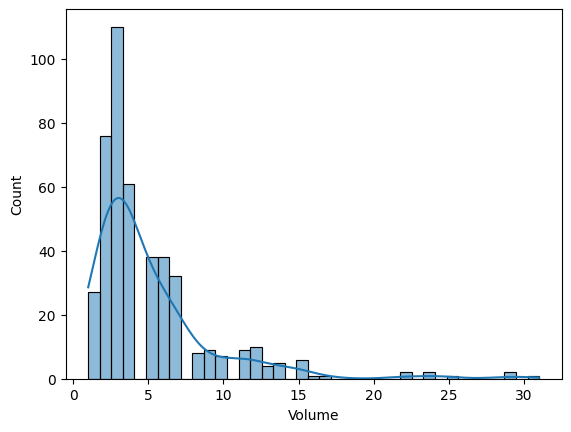

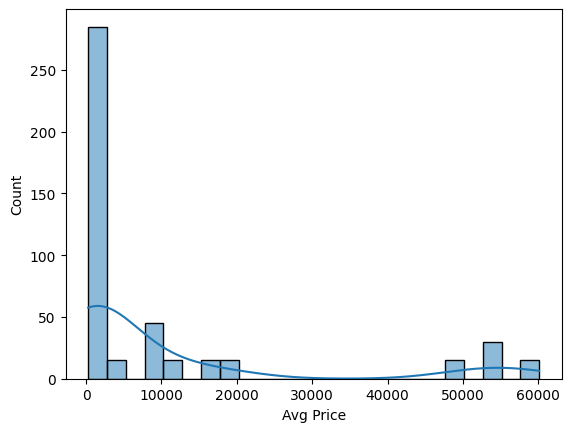

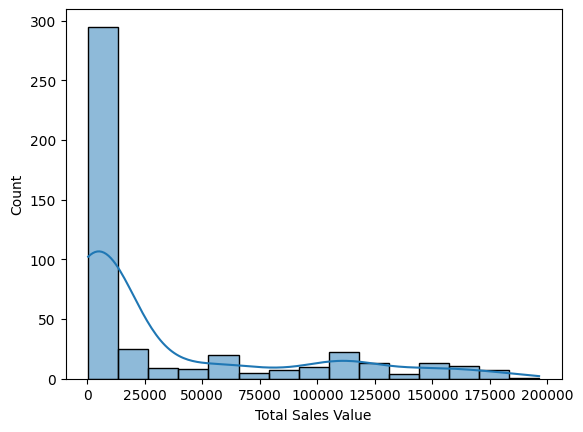

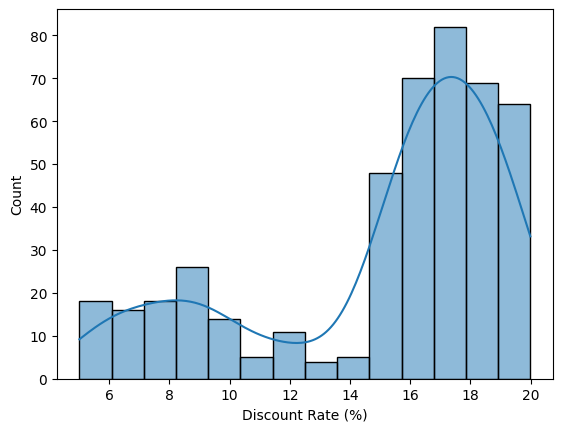

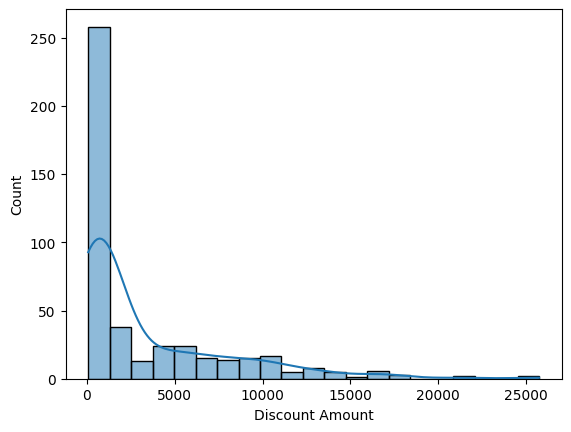

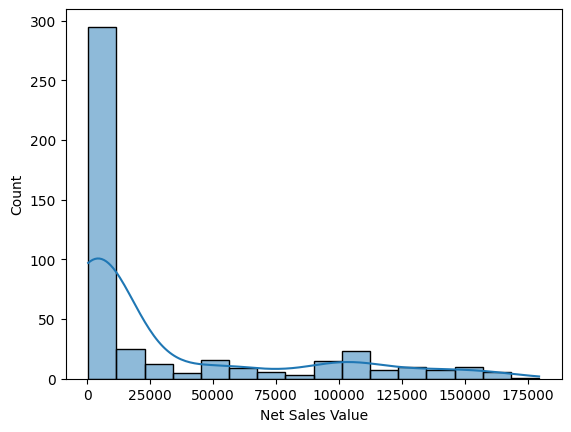

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
for i in sales_numerical:
  sns.histplot(sales_numerical[i], kde = True)
  plt.show()

# **Analysis from histogram of numerical data**

1-Almost all the numerical datas/columns are *right skewed/positively skewed* suggesting *mean > median* (also the data is concentrated to the left side or lower side)These values are 'Volume', 'Avg Price', 'Total Sales Value', ,'Discount Amount', 'Net Sales Value'

2-Only the 'Discount Rate (%)' data/column is *left skewed/negatively skewed* suggesting *mean < median*(also the data is concentrated to the right side or higher side)

In [ ]:
skew_df = sales_numerical.skew()
skew_df

,0
Volume,2.731724
Avg Price,1.908873
Total Sales Value,1.534729
Discount Rate (%),-1.062294
Discount Amount,1.913038
Net Sales Value,1.540822


Interpreting Skewness Values:

Approximately Symmetrical Distribution: Skewness between -0.5 and 0.5.

Moderately Skewed Distribution: Skewness between -1 and -0.5 (negative) or 0.5 and 1 (positive).

Highly Skewed Distribution: Skewness less than -1 (negative) or greater than 1 (positive).




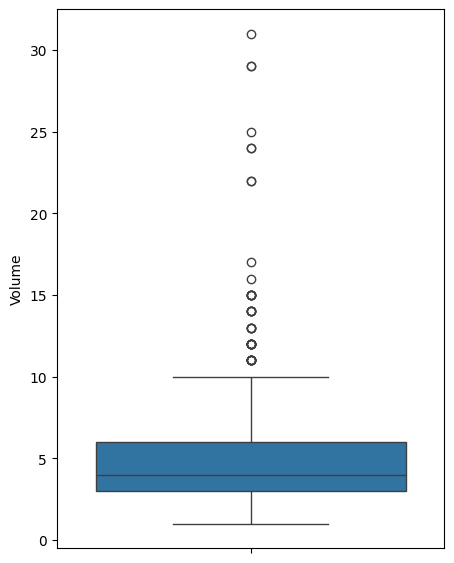

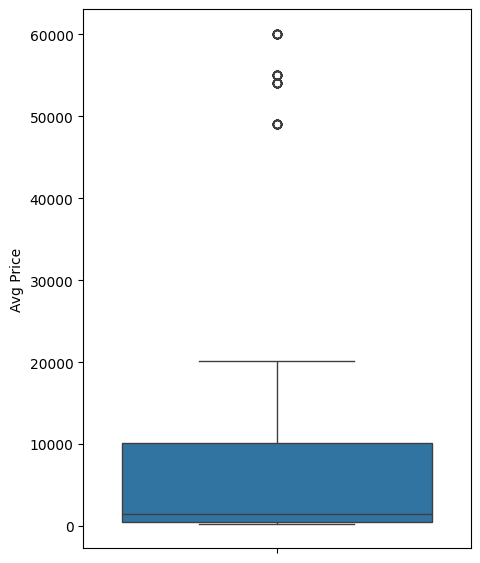

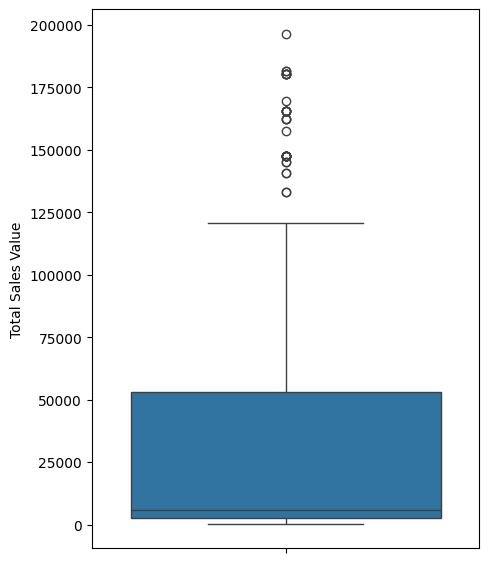

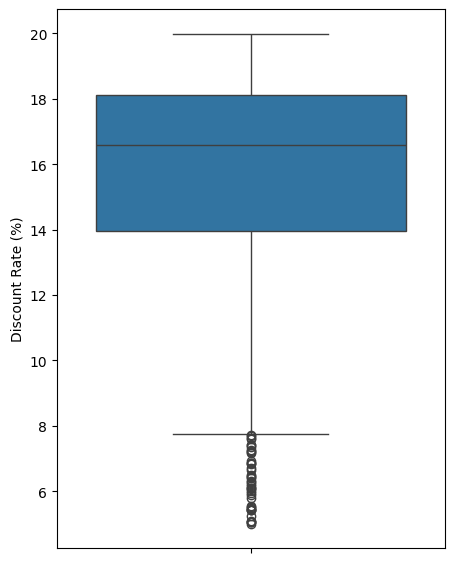

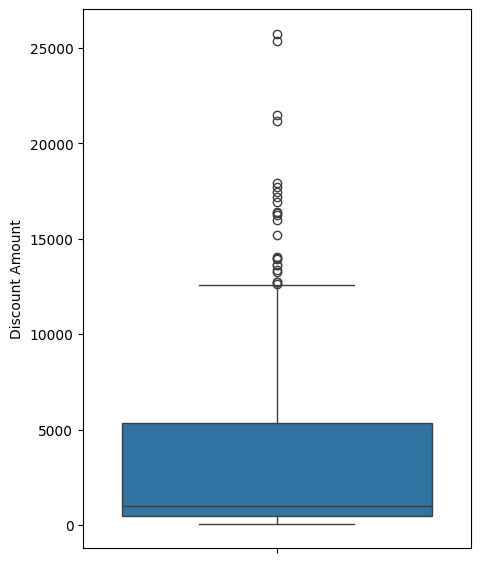

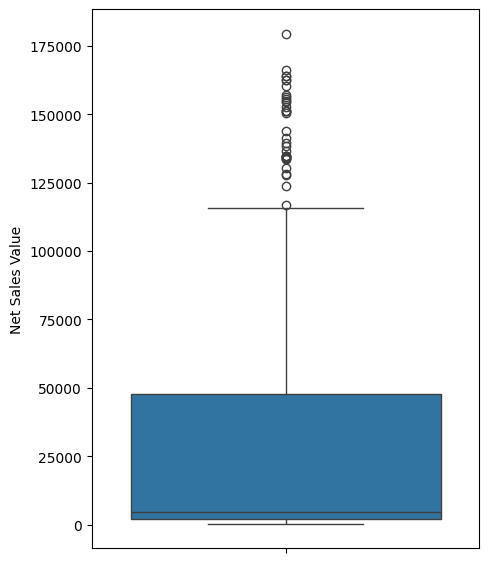

In [ ]:

for i in sales_numerical:
  plt.figure(figsize=(5,7))
  sns.boxplot(sales_numerical[i])
  plt.show()

In [ ]:
for i in sales_numerical:
  Q1 = sales_numerical[i].quantile(0.25)
  Q3 = sales_numerical[i].quantile(0.75)
  IQR = Q3 - Q1
  print('1st Quartile value for ',i, ' is:- ', Q1)
  print('3rd Quartile value for ',i, ' is:- ', Q3)
  print('Inter Quartile Range for ',i, ' is:- ', IQR)
  print('________________________________________\n')

1st Quartile value for  Volume  is:-  3.0
3rd Quartile value for  Volume  is:-  6.0
Inter Quartile Range for  Volume  is:-  3.0
________________________________________

1st Quartile value for  Avg Price  is:-  465.0
3rd Quartile value for  Avg Price  is:-  10100.0
Inter Quartile Range for  Avg Price  is:-  9635.0
________________________________________

1st Quartile value for  Total Sales Value  is:-  2700.0
3rd Quartile value for  Total Sales Value  is:-  53200.0
Inter Quartile Range for  Total Sales Value  is:-  50500.0
________________________________________

1st Quartile value for  Discount Rate (%)  is:-  13.965062543701741
3rd Quartile value for  Discount Rate (%)  is:-  18.114718477752703
Inter Quartile Range for  Discount Rate (%)  is:-  4.149655934050962
________________________________________

1st Quartile value for  Discount Amount  is:-  460.4593038855329
3rd Quartile value for  Discount Amount  is:-  5316.4954266866525
Inter Quartile Range for  Discount Amount  is:-  4

In [ ]:
for i in sales_numerical:
  Q1 = sales_numerical[i].quantile(0.25)
  Q3 = sales_numerical[i].quantile(0.75)
  IQR = Q3 - Q1
  outliers = sales_numerical[i][(sales_numerical[i] < (Q1 - 1.5 * IQR)) | (sales_numerical[i] > (Q3 + 1.5 * IQR))]
  print('Number of outliers for ',i,'dataset is:- ',len(outliers))


Number of outliers for  Volume dataset is:-  44
Number of outliers for  Avg Price dataset is:-  60
Number of outliers for  Total Sales Value dataset is:-  36
Number of outliers for  Discount Rate (%) dataset is:-  45
Number of outliers for  Discount Amount dataset is:-  24
Number of outliers for  Net Sales Value dataset is:-  35


In [ ]:
sales_categorical = sales.select_dtypes(exclude='number')
sales_categorical.columns

Index(['Date', 'Day', 'SKU', 'City', 'BU', 'Brand', 'Model'], dtype='object')

In [ ]:
sales_categorical.head(10)

,Date,Day,SKU,City,BU,Brand,Model
0,01-04-2021,Thursday,M01,C,Mobiles,RealU,RU-10
1,01-04-2021,Thursday,M02,C,Mobiles,RealU,RU-9 Plus
2,01-04-2021,Thursday,M03,C,Mobiles,YouM,YM-99
3,01-04-2021,Thursday,M04,C,Mobiles,YouM,YM-99 Plus
4,01-04-2021,Thursday,M05,C,Mobiles,YouM,YM-98
5,01-04-2021,Thursday,M06,C,Mobiles,RealU,RU-9
6,01-04-2021,Thursday,M07,C,Mobiles,Sumsang,S-20
7,01-04-2021,Thursday,M08,C,Mobiles,Sumsang,S-21
8,01-04-2021,Thursday,M09,C,Mobiles,Orange,O-10
9,01-04-2021,Thursday,M10,C,Mobiles,Orange,O-11


In [ ]:
sales_categorical.shape

(450, 7)

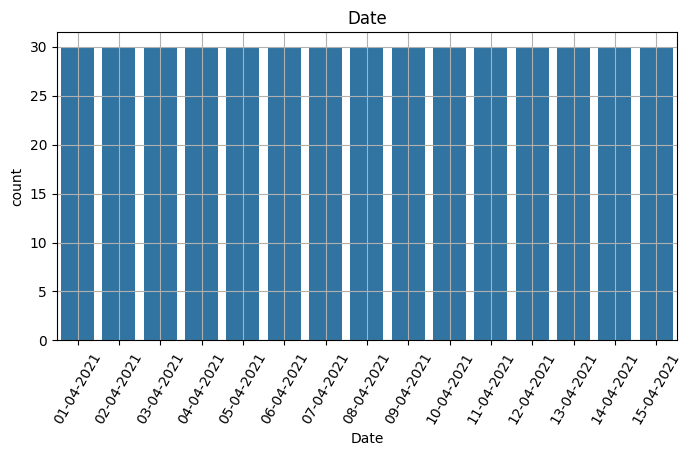

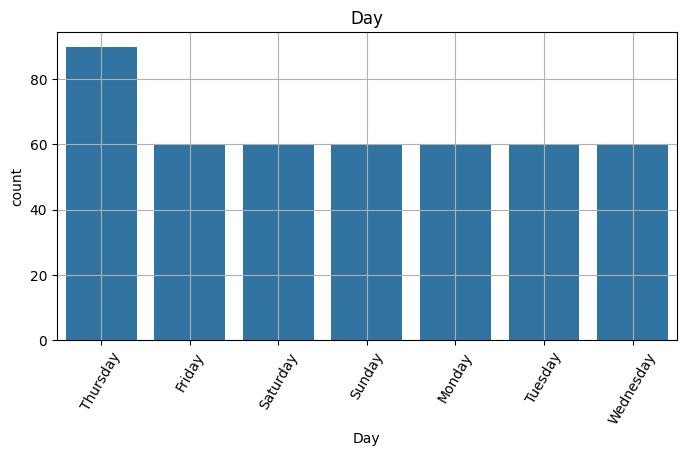

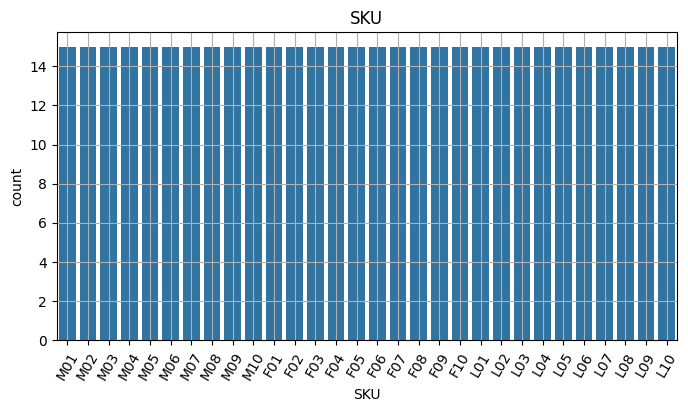

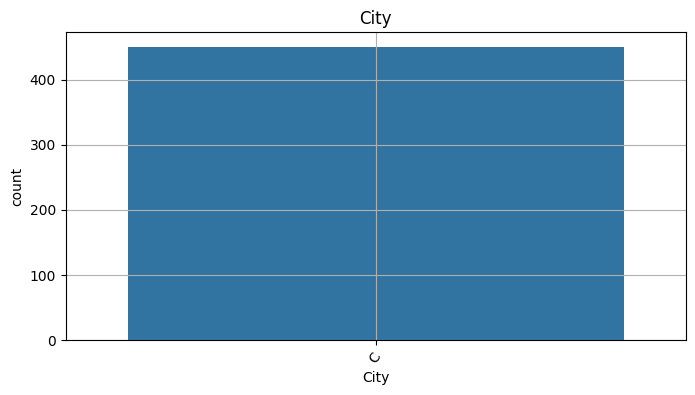

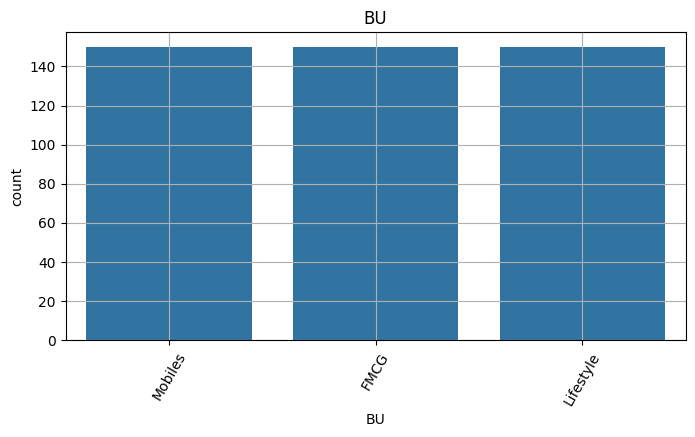

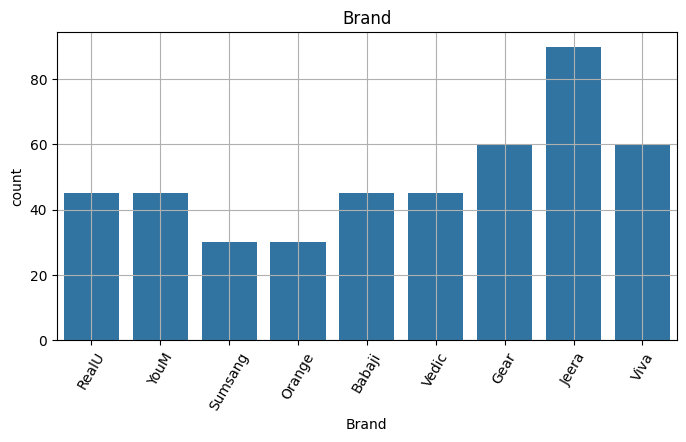

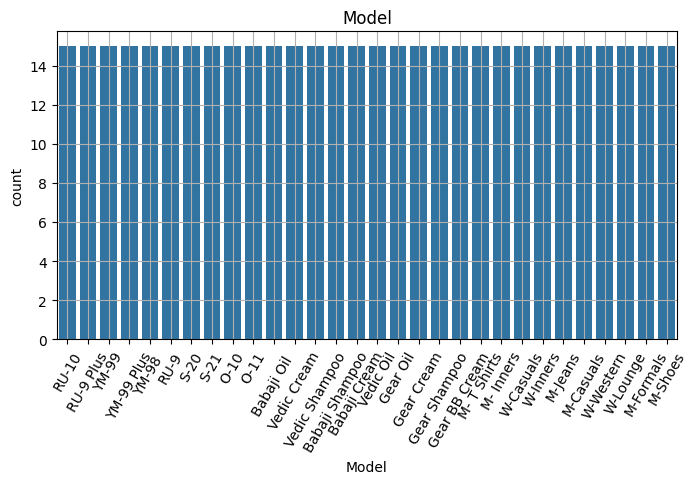

In [ ]:
for i in sales_categorical:
  plt.figure(figsize=(8,4))
  sns.countplot(x=sales_categorical[i])
  plt.title(i)
  plt.xticks(rotation=60)
  plt.grid()

In [ ]:
# Standardization of numerical data
df = pd.DataFrame()
for i in sales_numerical:
  df[i+'standardized'] = (sales_numerical[i] - sales_numerical[i].mean()) / sales_numerical[i].std()
  print(df[i+'standardized'])


0      2.347417
1      1.165831
2      0.456880
3      0.220563
4     -0.488389
         ...   
445   -0.724706
446    0.220563
447   -0.724706
448   -0.488389
449   -0.961023
Name: Volumestandardized, Length: 450, dtype: float64
0      0.091072
1     -0.019548
2      0.312312
3      0.533552
4     -0.130168
         ...   
445   -0.506277
446   -0.434374
447   -0.489684
448   -0.473091
449   -0.406719
Name: Avg Pricestandardized, Length: 450, dtype: float64
0      2.922469
1      1.329516
2      1.561038
3      1.717365
4     -0.188242
         ...   
445   -0.617647
446   -0.360400
447   -0.605774
448   -0.556303
449   -0.607753
Name: Total Sales Valuestandardized, Length: 450, dtype: float64
0     -0.829365
1     -0.851714
2     -1.350129
3     -1.947555
4      0.672990
         ...   
445    0.075924
446    0.450596
447    0.902788
448    0.388042
449    0.042188
Name: Discount Rate (%)standardized, Length: 450, dtype: float64
0      3.948422
1      1.846958
2      1.621190
3      

In [ ]:
sales_numerical_scale = pd.DataFrame()
for i in sales_numerical:
  sales_numerical_scale[i+'scaled'] = (sales_numerical[i] - sales_numerical[i].mean()) / sales_numerical[i].std()
display(sales_numerical_scale)

,Volumescaled,Avg Pricescaled,Total Sales Valuescaled,Discount Rate (%)scaled,Discount Amountscaled,Net Sales Valuescaled
0,2.347417,0.091072,2.922469,-0.829365,3.948422,2.801638
1,1.165831,-0.019548,1.329516,-0.851714,1.846958,1.269613
2,0.456880,0.312312,1.561038,-1.350129,1.621190,1.543957
3,0.220563,0.533552,1.717365,-1.947555,1.112568,1.763847
4,-0.488389,-0.130168,-0.188242,0.672990,0.227598,-0.227342
...,...,...,...,...,...,...
445,-0.724706,-0.506277,-0.617647,0.075924,-0.652815,-0.609783
446,0.220563,-0.434374,-0.360400,0.450596,-0.152022,-0.378079
447,-0.724706,-0.489684,-0.605774,0.902788,-0.607464,-0.601252
448,-0.488389,-0.473091,-0.556303,0.388042,-0.529789,-0.554881



 
 
 The data distribution before standardization:



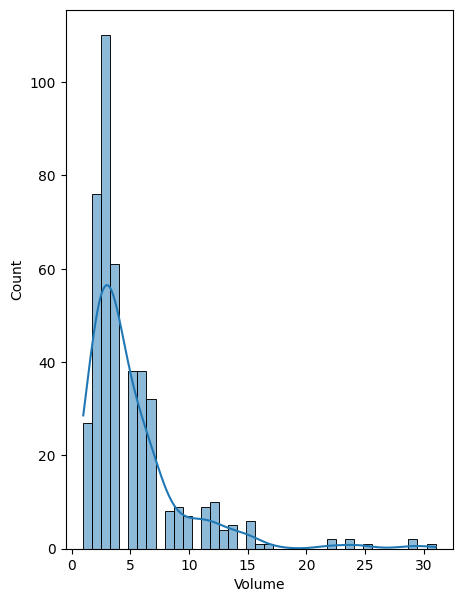


 
 
 The data distribution after standardization:



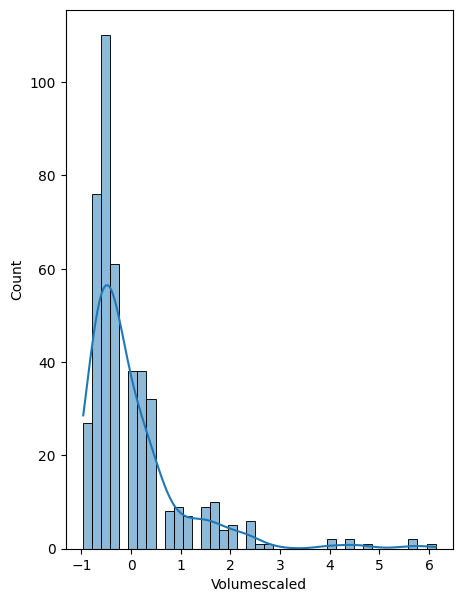


 
 
 The data distribution before standardization:



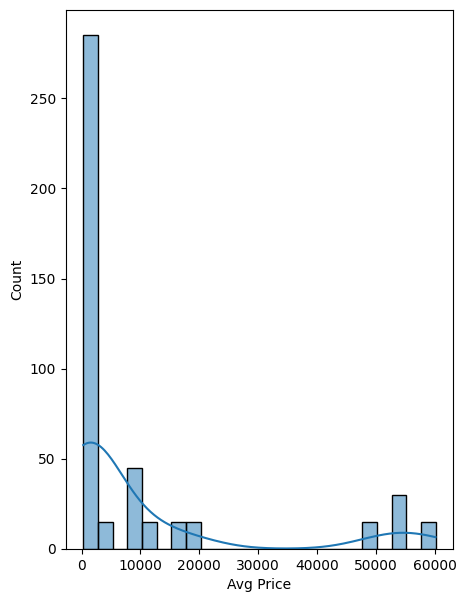


 
 
 The data distribution after standardization:



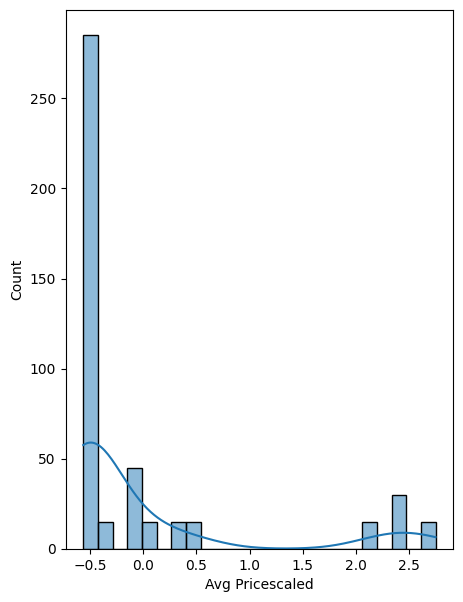


 
 
 The data distribution before standardization:



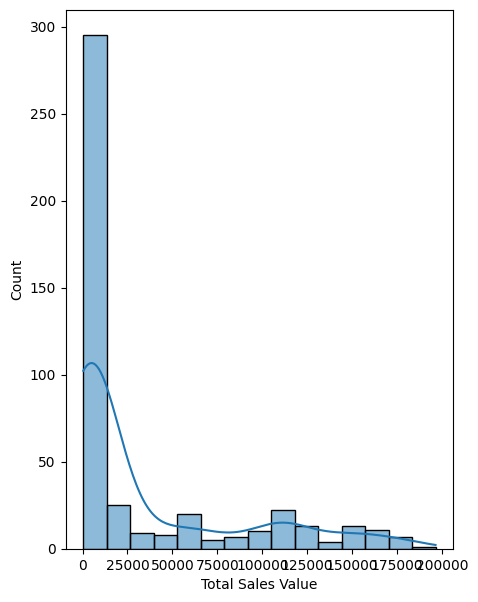


 
 
 The data distribution after standardization:



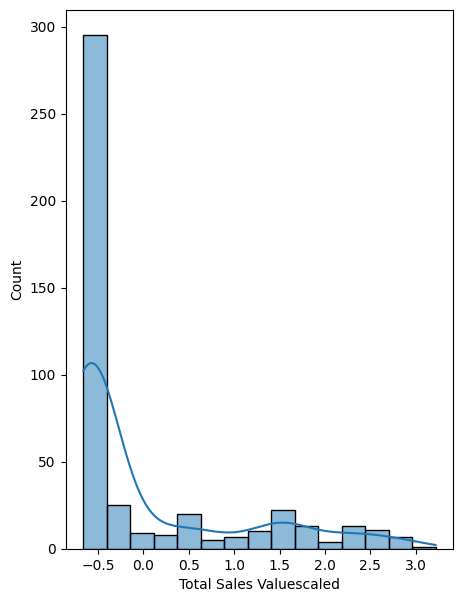


 
 
 The data distribution before standardization:



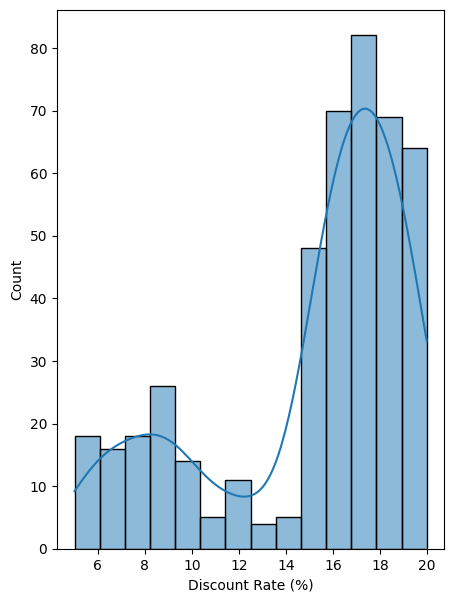


 
 
 The data distribution after standardization:



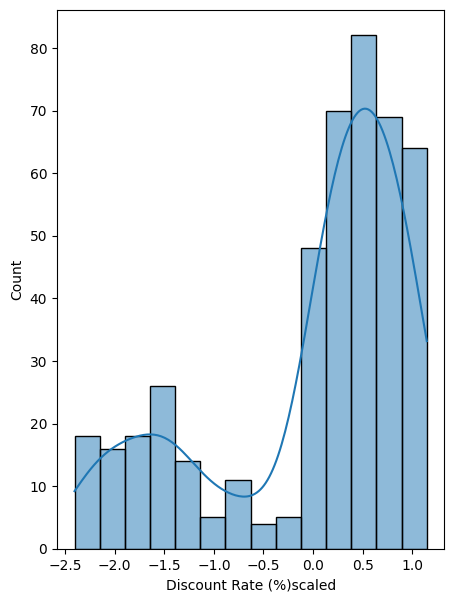


 
 
 The data distribution before standardization:



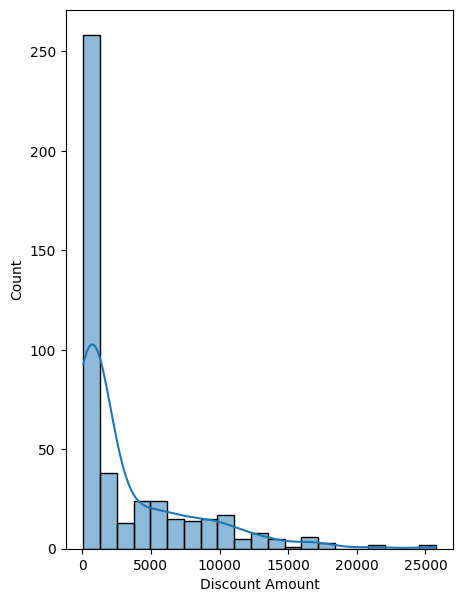


 
 
 The data distribution after standardization:



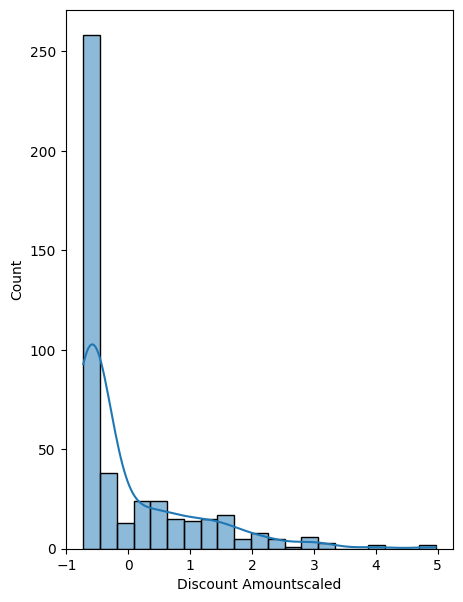


 
 
 The data distribution before standardization:



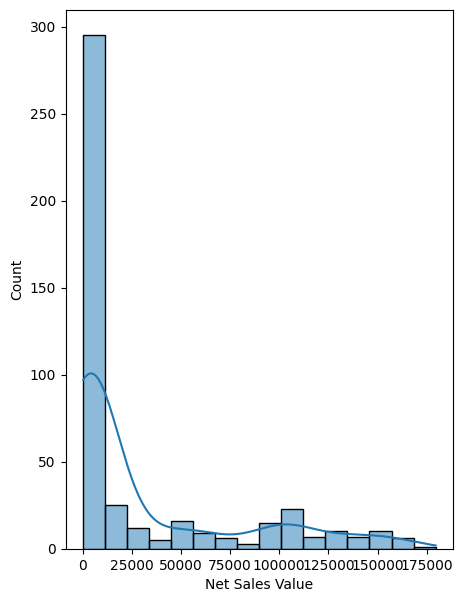


 
 
 The data distribution after standardization:



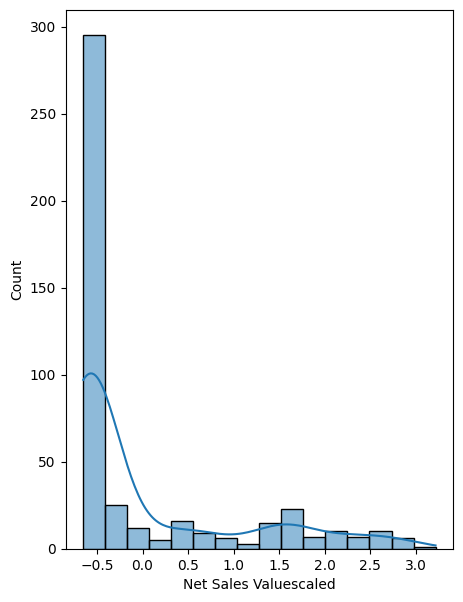

In [ ]:
for i in sales_numerical:
  print('\n \n \n The data distribution before standardization:\n')
  plt.figure(figsize=(5,7))
  sns.histplot(sales_numerical[i], kde = True)
  plt.show()

  print('\n \n \n The data distribution after standardization:\n')
  plt.figure(figsize=(5,7))
  sns.histplot(sales_numerical_scale[i+'scaled'], kde = True)
  plt.show()

In [ ]:
sales_numerical = pd.concat([sales_numerical, sales_numerical_scale], axis=1)
sales_numerical.head()

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value,Volumescaled,Avg Pricescaled,Total Sales Valuescaled,Discount Rate (%)scaled,Discount Amountscaled,Net Sales Valuescaled
0,15,12100,181500,11.654820,21153.498820,160346.501180,2.347417,0.091072,2.922469,-0.829365,3.948422,2.801638
1,10,10100,101000,11.560498,11676.102961,89323.897039,1.165831,-0.019548,1.329516,-0.851714,1.846958,1.269613
2,7,16100,112700,9.456886,10657.910157,102042.089843,0.456880,0.312312,1.561038,-1.350129,1.621190,1.543957
3,6,20100,120600,6.935385,8364.074702,112235.925298,0.220563,0.533552,1.717365,-1.947555,1.112568,1.763847
4,3,8100,24300,17.995663,4372.946230,19927.053770,-0.488389,-0.130168,-0.188242,0.672990,0.227598,-0.227342


In [ ]:
sales_categorical

,Date,Day,SKU,City,BU,Brand,Model
0,01-04-2021,Thursday,M01,C,Mobiles,RealU,RU-10
1,01-04-2021,Thursday,M02,C,Mobiles,RealU,RU-9 Plus
2,01-04-2021,Thursday,M03,C,Mobiles,YouM,YM-99
3,01-04-2021,Thursday,M04,C,Mobiles,YouM,YM-99 Plus
4,01-04-2021,Thursday,M05,C,Mobiles,YouM,YM-98
...,...,...,...,...,...,...,...
445,15-04-2021,Thursday,L06,C,Lifestyle,Jeera,M-Casuals
446,15-04-2021,Thursday,L07,C,Lifestyle,Viva,W-Western
447,15-04-2021,Thursday,L08,C,Lifestyle,Viva,W-Lounge
448,15-04-2021,Thursday,L09,C,Lifestyle,Jeera,M-Formals


In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
encoded_df = pd.DataFrame(encoder.fit_transform(sales_categorical), columns=encoder.get_feature_names_out(sales_categorical.columns))
df_one = pd.concat([sales_categorical.drop(columns=sales_categorical.columns), encoded_df], axis=1)
df_one

,Date_01-04-2021,Date_02-04-2021,Date_03-04-2021,Date_04-04-2021,Date_05-04-2021,Date_06-04-2021,Date_07-04-2021,Date_08-04-2021,Date_09-04-2021,Date_10-04-2021,...,Model_Vedic Cream,Model_Vedic Oil,Model_Vedic Shampoo,Model_W-Casuals,Model_W-Inners,Model_W-Lounge,Model_W-Western,Model_YM-98,Model_YM-99,Model_YM-99 Plus
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
446,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
447,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
448,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
sales = sales.drop(columns = sales_categorical.columns)
sales = pd.concat([sales, df_one], axis=1)
sales

,Volume,Avg Price,Total Sales Value,Discount Rate (%),Discount Amount,Net Sales Value,Date_01-04-2021,Date_02-04-2021,Date_03-04-2021,Date_04-04-2021,...,Model_Vedic Cream,Model_Vedic Oil,Model_Vedic Shampoo,Model_W-Casuals,Model_W-Inners,Model_W-Lounge,Model_W-Western,Model_YM-98,Model_YM-99,Model_YM-99 Plus
0,15,12100,181500,11.654820,21153.498820,160346.501180,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,10,10100,101000,11.560498,11676.102961,89323.897039,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,7,16100,112700,9.456886,10657.910157,102042.089843,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,6,20100,120600,6.935385,8364.074702,112235.925298,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,3,8100,24300,17.995663,4372.946230,19927.053770,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,2,1300,2600,15.475687,402.367873,2197.632127,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
446,6,2600,15600,17.057027,2660.896242,12939.103758,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
447,2,1600,3200,18.965550,606.897606,2593.102394,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
448,3,1900,5700,16.793014,957.201826,4742.798174,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
sales.shape

(450, 101)